In [41]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from shapely.geometry import Polygon
import numpy as np
import cartopy.io.img_tiles as cimgt
import cartopy.feature as cfeature
from matplotlib.patches import Rectangle
import pandas as pd
from cartopy.io.shapereader import Reader as ShapeReader
import contextily as ctx
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import glob
import os


In [20]:
def read_mar_var(path_pattern, var_names, months=[11, 12, 1, 2, 3], time_slice=('19800101', '20220331')):
    """
    Reads MAR NetCDF files, selects specified variables and dimensions,
    filters by months and time range.

    Parameters:
        path_pattern (str): File path pattern for NetCDF files.
        var_names (list): List of variable names to extract.
        months (list, optional): Months to filter. Default is summer in Patagonia.
        time_slice (tuple, optional): Start and end date for filtering. Default is ('19800101', '20220331').

    Returns:
        xarray.Dataset: Concatenated and filtered dataset.
    """
    files = sorted(glob.glob(path_pattern))
    ds_list = []

    for f in files:
        ds = xr.open_dataset(f).isel(ATMLAY3_3=0, SECTOR=0, SECTOR1_1=0)[var_names]
        ds = ds.sel(TIME=ds['TIME'].dt.month.isin(months))
        ds['TIME'] = ds['TIME'].dt.floor('D')
        ds_list.append(ds)

    ds_combined = xr.concat(ds_list, dim='TIME').sel(TIME=slice(*time_slice))
    return ds_combined


def read_mar_var_AP(path_pattern, var_names, months=[11, 12, 1, 2, 3], time_slice=('19800101', '20220331')):
    """
    Reads MAR NetCDF files, selects specified variables and dimensions,
    filters by months and time range.

    Parameters:
        path_pattern (str): File path pattern for NetCDF files.
        var_names (list): List of variable names to extract.
        months (list, optional): Months to filter. Default is summer in Patagonia.
        time_slice (tuple, optional): Start and end date for filtering. Default is ('19800101', '20220331').

    Returns:
        xarray.Dataset: Concatenated and filtered dataset.
    """
    files = sorted(glob.glob(path_pattern))
    ds_list = []

    for f in files:
        ds = xr.open_dataset(f).sel(X = slice(-2660, -2120), Y= slice(800, 1700)).isel(SECTOR=0, SECTOR1_1=0, ATMLAY=0)[var_names]
        ds = ds.sel(TIME=ds['TIME'].dt.month.isin(months))
        ds['TIME'] = ds['TIME'].dt.floor('D')
        ds_list.append(ds)

    ds_combined = xr.concat(ds_list, dim='TIME').sel(TIME=slice(*time_slice))
    return ds_combined

def compute_daily_anomalies(ds: xr.DataArray, time_dim: str = "time") -> xr.DataArray:
    """
    Compute daily anomalies of a temperature field based on day-of-year climatology.
    
    Parameters:
        ds (xr.DataArray): Input data with a time dimension (e.g., daily temperature).
        time_dim (str): Name of the time dimension (default is 'time').

    Returns:
        anomalies (xr.DataArray): Daily anomalies with same shape as input.
    """

    # Create dayofyear coordinate
    doy = ds[time_dim].dt.dayofyear
    ds = ds.assign_coords(dayofyear=(time_dim, doy.data))

    # Compute climatology (mean for each day of the year)
    climatology = ds.groupby("dayofyear").mean(time_dim)

    # Subtract climatology to get anomalies
    anomalies = ds.groupby("dayofyear") - climatology

    return anomalies


In [ ]:
# -----------------------------------------------------------------------------
# Plot configuration
# -----------------------------------------------------------------------------
plt.rcParams.update({
    "font.size": 16,
    "axes.labelsize": 18,
    "axes.titlesize": 20,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14
})

In [28]:
files = sorted(glob.glob('/home/cr2/cmtorres/MAR_DATA_SEL/Patagonia/*.nc'))
ds_MAR = xr.open_dataset(files[0])
LAT = ds_MAR['LAT']
LON = ds_MAR['LON']

files = sorted(glob.glob('/home/cr2/cmtorres/MAR_DATA_SEL/APeninsula/*.nc'))
ds_MAR_AP = xr.open_dataset(files[0]).sel(X = slice(-2660, -2120), Y= slice(800, 1700))
LAT_AP = ds_MAR_AP['LAT']
LON_AP = ds_MAR_AP['LON']

In [56]:
path_pattern='/home/cr2/cmtorres/MAR_DATA_SEL/Patagonia/*.nc'
ds_TT = read_mar_var( path_pattern=path_pattern, var_names=['TT'])
T2_anom = compute_daily_anomalies(ds_TT['TT'], time_dim= "TIME")
ds_RF = read_mar_var( path_pattern=path_pattern, var_names=['RF'])
ds_SF = read_mar_var( path_pattern=path_pattern, var_names=['SF'])
RRR = ds_RF.RF + ds_SF.SF


path_pattern='/home/cr2/cmtorres/MAR_DATA_SEL/APeninsula/*.nc'
ds_TT_AP = read_mar_var_AP( path_pattern=path_pattern, var_names=['TT'])

T2_anom_AP = compute_daily_anomalies(ds_TT_AP['TT'], time_dim= "TIME")

ds_RF_AP = read_mar_var_AP( path_pattern=path_pattern, var_names=['RF'])
ds_SF_AP = read_mar_var_AP( path_pattern=path_pattern, var_names=['SF'])
RRR_AP = ds_RF_AP.RF + ds_SF_AP.SF



In [63]:
# Map setup function
def setup_map(ax, proj_data):
    lonW, lonE = -80, -48
    latN, latS = -45, -70
    ax.set_extent([lonW, lonE, latS, latN], crs=proj_data)
    ax.coastlines(resolution='110m')
    ax.add_feature(cfeature.BORDERS, linestyle=':')
    ax.add_feature(cfeature.LAND, facecolor='none')
    ax.set_adjustable('box')


./fig/map_MAR_RRR_case_2019.png


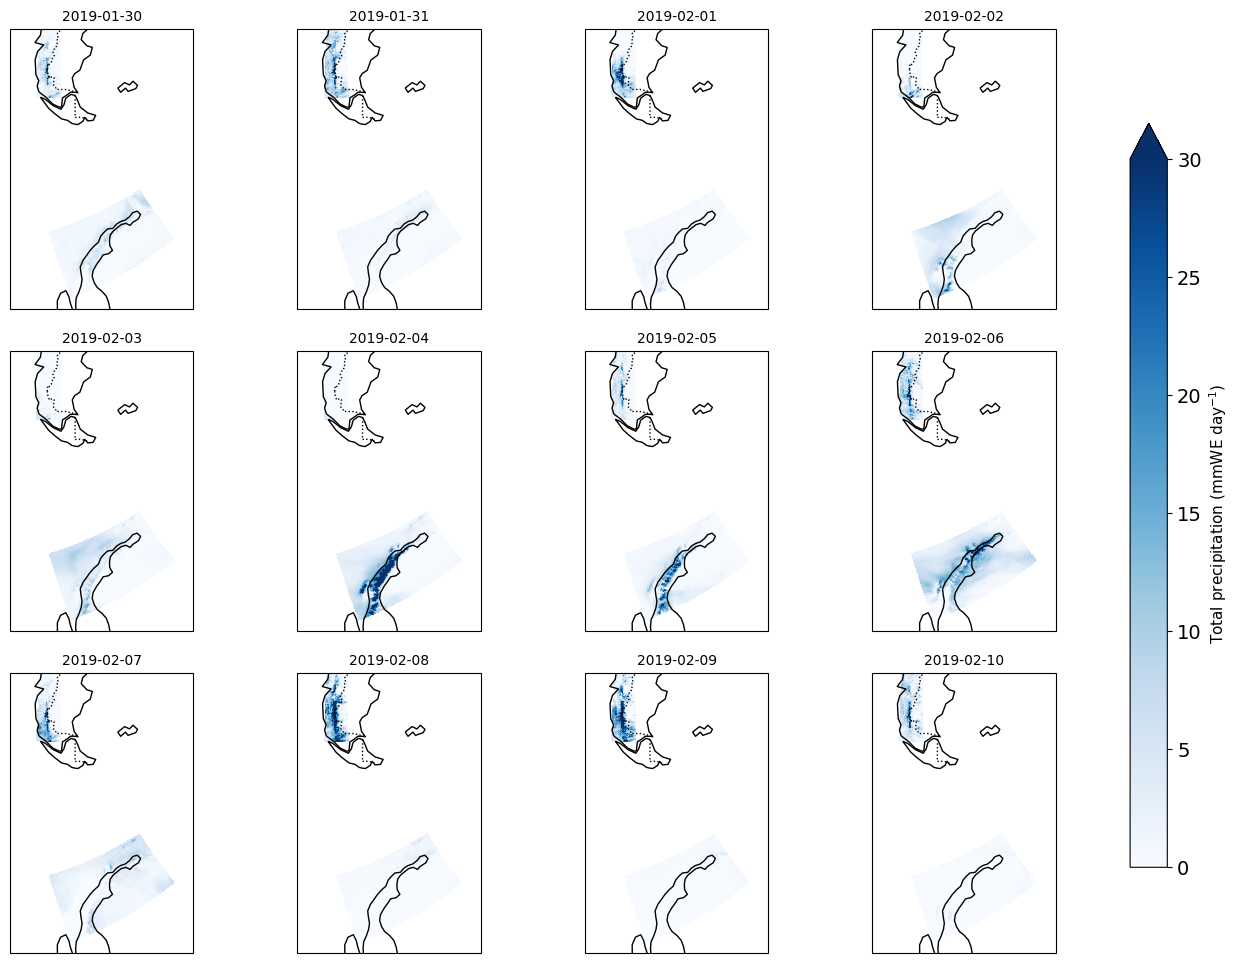

In [68]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Projections
proj_map = ccrs.Mercator()
proj_data = ccrs.PlateCarree()

date_start = '20190130'
date_end   = '20190210'

RRR_sel = RRR.sel(TIME=slice(date_start, date_end))
RRR_AP_sel = RRR_AP.sel(TIME=slice(date_start, date_end))


# Create 3x4 layout
fig, axes = plt.subplots(
    3,
    4,
    figsize=(16, 12),
    subplot_kw={"projection": proj_map},
    gridspec_kw={"wspace": 0.08, "hspace": 0.15},
)

# Flatten axes array for straightforward iteration
axes_flat = axes.flatten()
cmap_precip = 'Blues'
mesh = None
num_times = len(RRR_sel.TIME)
levels_precip = np.arange(0, 15, 1.0)

# Loop over each timestep (up to 12 max for a 3x4 layout)
for i in range(min(num_times, 12)):
    ax = axes_flat[i]
    setup_map(ax, proj_data=proj_data)
    
    # Plot main data
    mesh = ax.pcolormesh(
        LON, LAT, RRR_sel.isel(TIME=i), vmin=0, vmax=30,
        cmap=cmap_precip, shading="auto", transform=proj_data
    )
    
    # Plot AP data overlay
    ax.pcolormesh(
        LON_AP, LAT_AP, RRR_AP_sel.isel(TIME=i),vmin=0, vmax=30,
        cmap=cmap_precip, shading="auto", transform=proj_data
    )
    
    # Extract date string for title
    time_str = str(RRR_sel.TIME.values[i])[:10]
    ax.set_title(time_str, fontsize=10)

# Hide any unused subplots if TIME slice has fewer than 12 steps
for j in range(num_times, 12):
    fig.delaxes(axes_flat[j])

# Single horizontal colorbar across the bottom
cbar = plt.colorbar(
    mesh,
    ax=axes,
    orientation="vertical",
    fraction=0.03,
    pad=0.06,
    extend='max'
)
cbar.set_label("Total precipitation (mmWE day$^{-1}$)", fontsize=11)


# Output directory for saving images
output_dir = "./fig"
os.makedirs(output_dir, exist_ok=True)

# Save figure named by date and close to free memory
save_path = os.path.join(output_dir, f"map_MAR_RRR_case_2019.png")
print(save_path)
plt.savefig(save_path, dpi=200, bbox_inches="tight")


./fig/map_MAR_RRR_case_2020.png


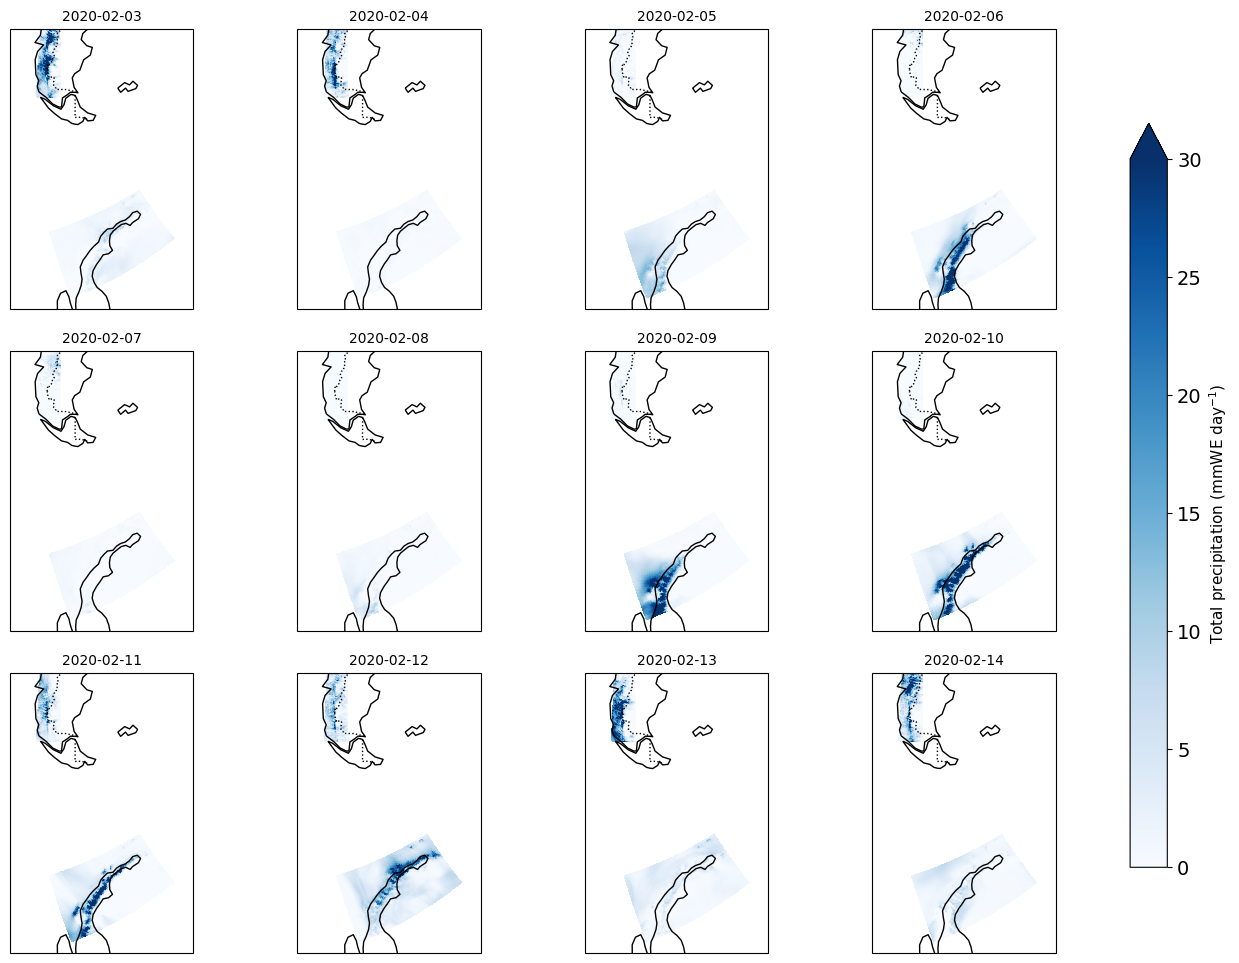

In [69]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Projections
proj_map = ccrs.Mercator()
proj_data = ccrs.PlateCarree()

date_start = '20200203'
date_end   = '20200214'

RRR_sel = RRR.sel(TIME=slice(date_start, date_end))
RRR_AP_sel = RRR_AP.sel(TIME=slice(date_start, date_end))


# Create 3x4 layout
fig, axes = plt.subplots(
    3,
    4,
    figsize=(16, 12),
    subplot_kw={"projection": proj_map},
    gridspec_kw={"wspace": 0.08, "hspace": 0.15},
)

# Flatten axes array for straightforward iteration
axes_flat = axes.flatten()

mesh = None
num_times = len(RRR_sel.TIME)
levels_precip = np.arange(0, 15, 1.0)

# Loop over each timestep (up to 12 max for a 3x4 layout)
for i in range(min(num_times, 12)):
    ax = axes_flat[i]
    setup_map(ax, proj_data=proj_data)
    
    # Plot main data
    mesh = ax.pcolormesh(
        LON, LAT, RRR_sel.isel(TIME=i), vmin=0, vmax=30,
        cmap=cmap_precip, shading="auto", transform=proj_data
    )
    
    # Plot AP data overlay
    ax.pcolormesh(
        LON_AP, LAT_AP, RRR_AP_sel.isel(TIME=i),vmin=0, vmax=30,
        cmap=cmap_precip, shading="auto", transform=proj_data
    )
    
    # Extract date string for title
    time_str = str(RRR_sel.TIME.values[i])[:10]
    ax.set_title(time_str, fontsize=10)

# Hide any unused subplots if TIME slice has fewer than 12 steps
for j in range(num_times, 12):
    fig.delaxes(axes_flat[j])

# Single horizontal colorbar across the bottom
cbar = plt.colorbar(
    mesh,
    ax=axes,
    orientation="vertical",
    fraction=0.03,
    pad=0.06,
    extend='max'
)
cbar.set_label("Total precipitation (mmWE day$^{-1}$)", fontsize=11)


# Output directory for saving images
output_dir = "./fig"
os.makedirs(output_dir, exist_ok=True)

# Save figure named by date and close to free memory
save_path = os.path.join(output_dir, f"map_MAR_RRR_case_2020.png")
print(save_path)
plt.savefig(save_path, dpi=200, bbox_inches="tight")


./fig/map_MAR_RRR_case_2021.png


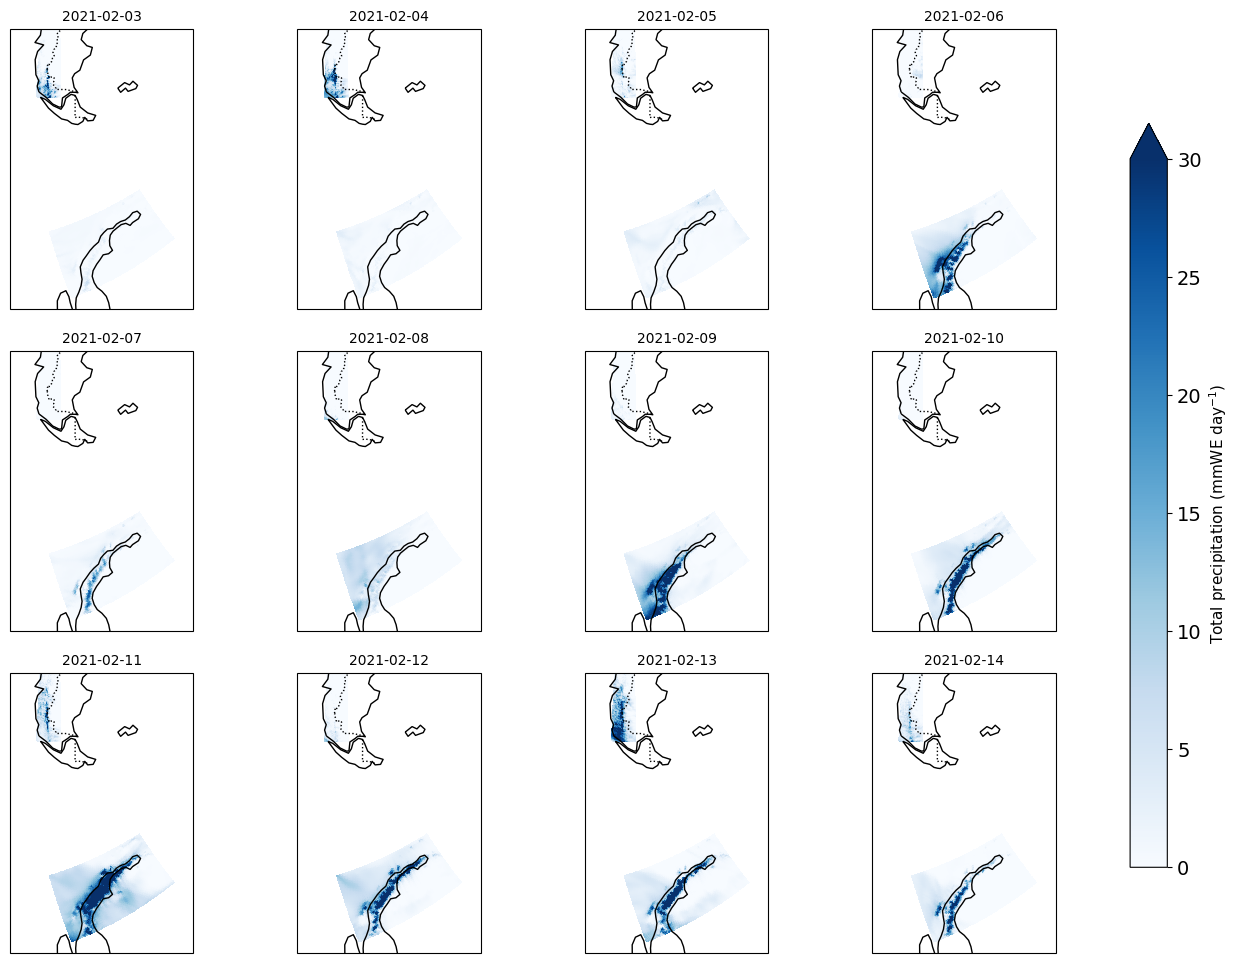

In [70]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Projections
proj_map = ccrs.Mercator()
proj_data = ccrs.PlateCarree()

date_start = '20210203'
date_end   = '20210214'

RRR_sel = RRR.sel(TIME=slice(date_start, date_end))
RRR_AP_sel = RRR_AP.sel(TIME=slice(date_start, date_end))


# Create 3x4 layout
fig, axes = plt.subplots(
    3,
    4,
    figsize=(16, 12),
    subplot_kw={"projection": proj_map},
    gridspec_kw={"wspace": 0.08, "hspace": 0.15},
)

# Flatten axes array for straightforward iteration
axes_flat = axes.flatten()

mesh = None
num_times = len(RRR_sel.TIME)
levels_precip = np.arange(0, 15, 1.0)

# Loop over each timestep (up to 12 max for a 3x4 layout)
for i in range(min(num_times, 12)):
    ax = axes_flat[i]
    setup_map(ax, proj_data=proj_data)
    
    # Plot main data
    mesh = ax.pcolormesh(
        LON, LAT, RRR_sel.isel(TIME=i), vmin=0, vmax=30,
        cmap=cmap_precip, shading="auto", transform=proj_data
    )
    
    # Plot AP data overlay
    ax.pcolormesh(
        LON_AP, LAT_AP, RRR_AP_sel.isel(TIME=i),vmin=0, vmax=30,
        cmap=cmap_precip, shading="auto", transform=proj_data
    )
    
    # Extract date string for title
    time_str = str(RRR_sel.TIME.values[i])[:10]
    ax.set_title(time_str, fontsize=10)

# Hide any unused subplots if TIME slice has fewer than 12 steps
for j in range(num_times, 12):
    fig.delaxes(axes_flat[j])

# Single horizontal colorbar across the bottom
cbar = plt.colorbar(
    mesh,
    ax=axes,
    orientation="vertical",
    fraction=0.03,
    pad=0.06,
    extend='max'
)
cbar.set_label("Total precipitation (mmWE day$^{-1}$)", fontsize=11)


# Output directory for saving images
output_dir = "./fig"
os.makedirs(output_dir, exist_ok=True)

# Save figure named by date and close to free memory
save_path = os.path.join(output_dir, f"map_MAR_RRR_case_2021.png")
print(save_path)
plt.savefig(save_path, dpi=200, bbox_inches="tight")


./fig/map_MAR_RRR_case_2022.png


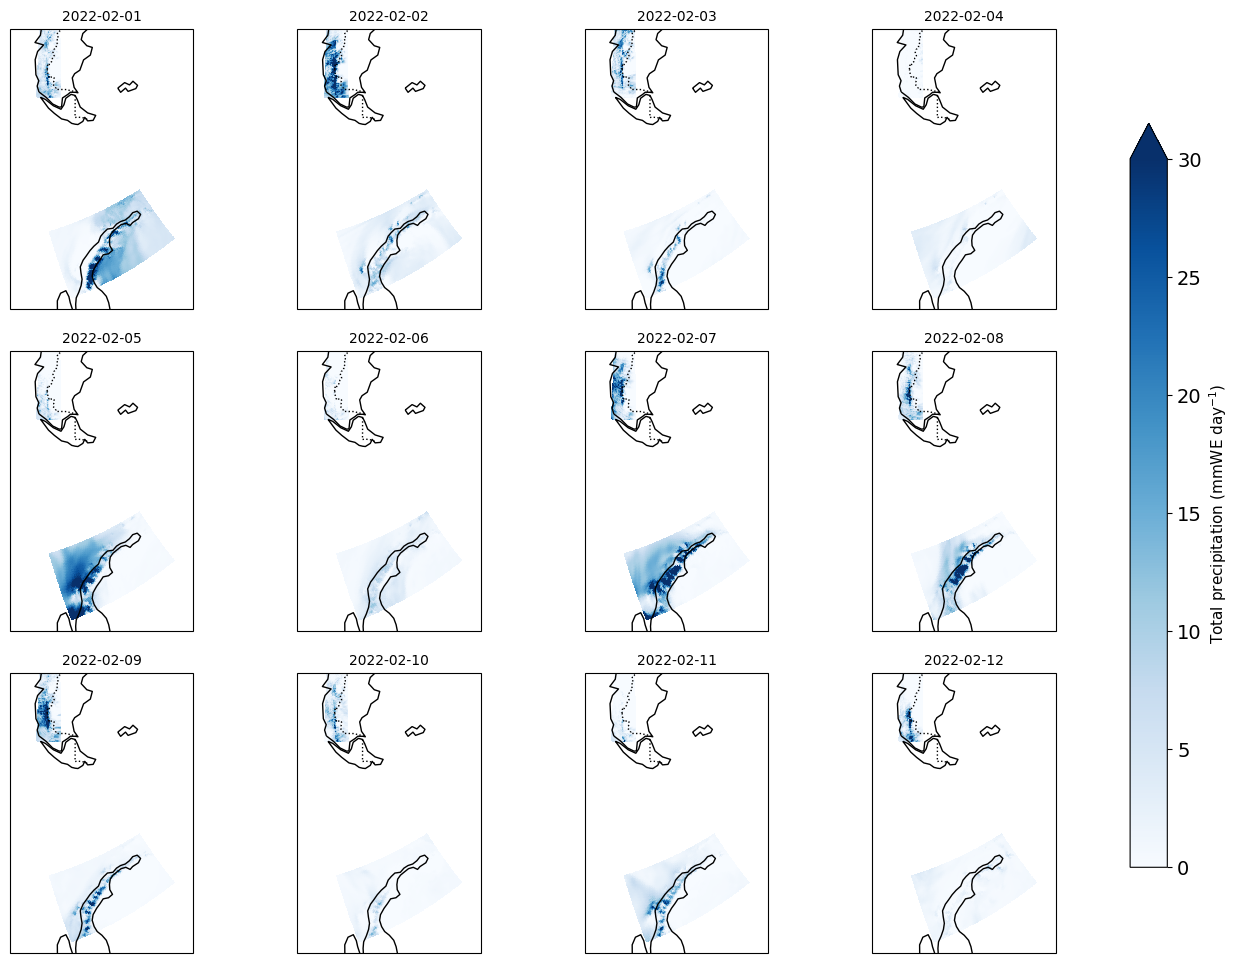

In [71]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Projections
proj_map = ccrs.Mercator()
proj_data = ccrs.PlateCarree()

date_start = '20220201'
date_end   = '20220212'

RRR_sel = RRR.sel(TIME=slice(date_start, date_end))
RRR_AP_sel = RRR_AP.sel(TIME=slice(date_start, date_end))


# Create 3x4 layout
fig, axes = plt.subplots(
    3,
    4,
    figsize=(16, 12),
    subplot_kw={"projection": proj_map},
    gridspec_kw={"wspace": 0.08, "hspace": 0.15},
)

# Flatten axes array for straightforward iteration
axes_flat = axes.flatten()

mesh = None
num_times = len(RRR_sel.TIME)
levels_precip = np.arange(0, 15, 1.0)

# Loop over each timestep (up to 12 max for a 3x4 layout)
for i in range(min(num_times, 12)):
    ax = axes_flat[i]
    setup_map(ax, proj_data=proj_data)
    
    # Plot main data
    mesh = ax.pcolormesh(
        LON, LAT, RRR_sel.isel(TIME=i), vmin=0, vmax=30,
        cmap=cmap_precip, shading="auto", transform=proj_data
    )
    
    # Plot AP data overlay
    ax.pcolormesh(
        LON_AP, LAT_AP, RRR_AP_sel.isel(TIME=i),vmin=0, vmax=30,
        cmap=cmap_precip, shading="auto", transform=proj_data
    )
    
    # Extract date string for title
    time_str = str(RRR_sel.TIME.values[i])[:10]
    ax.set_title(time_str, fontsize=10)

# Hide any unused subplots if TIME slice has fewer than 12 steps
for j in range(num_times, 12):
    fig.delaxes(axes_flat[j])

# Single horizontal colorbar across the bottom
cbar = plt.colorbar(
    mesh,
    ax=axes,
    orientation="vertical",
    fraction=0.03,
    pad=0.06,
    extend='max'
)
cbar.set_label("Total precipitation (mmWE day$^{-1}$)", fontsize=11)


# Output directory for saving images
output_dir = "./fig"
os.makedirs(output_dir, exist_ok=True)

# Save figure named by date and close to free memory
save_path = os.path.join(output_dir, f"map_MAR_RRR_case_2022.png")
print(save_path)
plt.savefig(save_path, dpi=200, bbox_inches="tight")


./fig/map_MAR_TT_case_2019.png


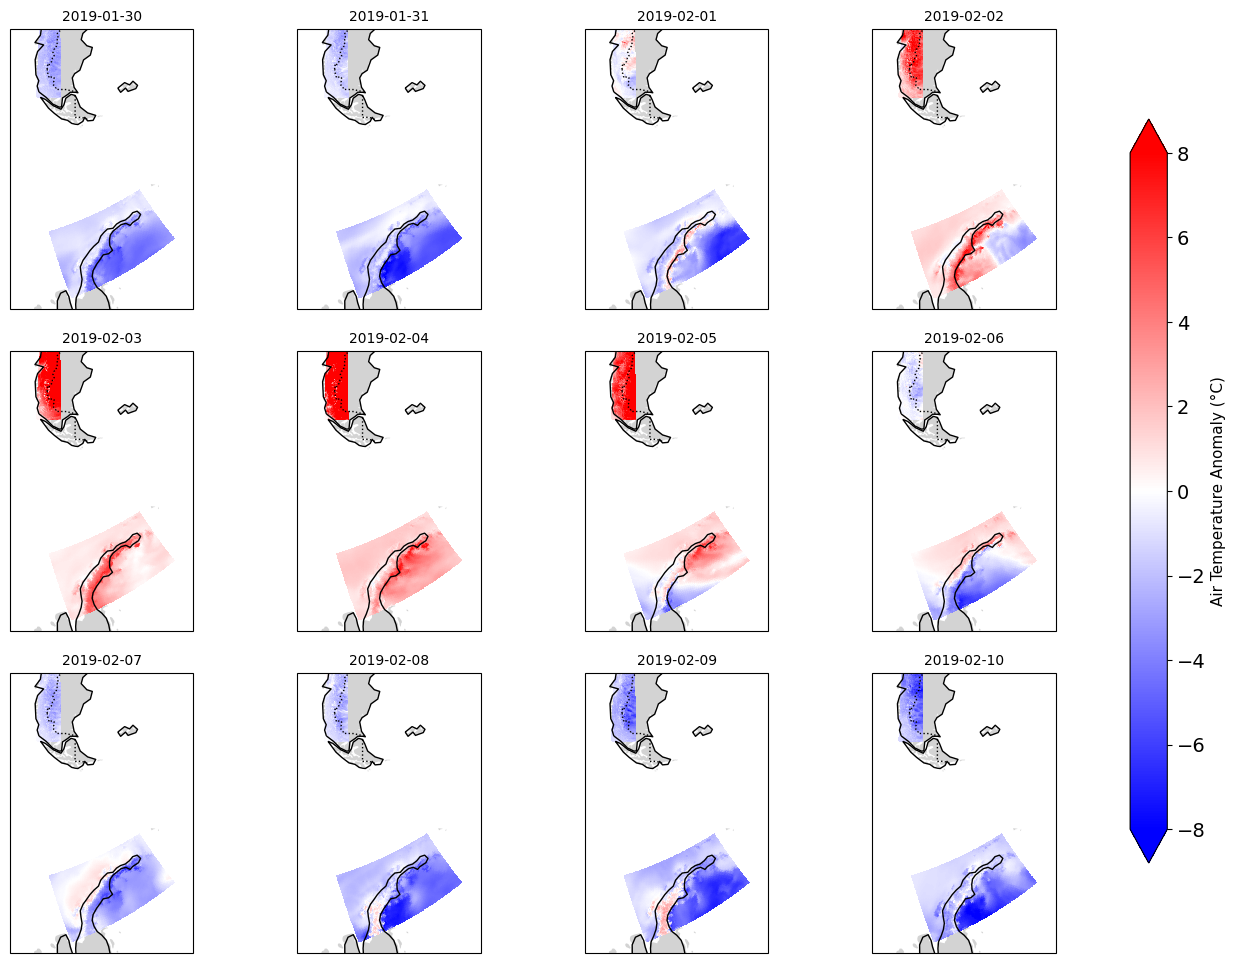

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Projections
proj_map = ccrs.Mercator()
proj_data = ccrs.PlateCarree()

date_start = '20190130'
date_end   = '20190210'

T2_anom_sel = T2_anom.sel(TIME=slice(date_start, date_end))
T2_anom_AP_sel = T2_anom_AP.sel(TIME=slice(date_start, date_end))


# Create 3x4 layout
fig, axes = plt.subplots(
    3,
    4,
    figsize=(16, 12),
    subplot_kw={"projection": proj_map},
    gridspec_kw={"wspace": 0.08, "hspace": 0.15},
)

# Flatten axes array for straightforward iteration
axes_flat = axes.flatten()

mesh = None
num_times = len(T2_anom_sel.TIME)

# Loop over each timestep (up to 12 max for a 3x4 layout)
for i in range(min(num_times, 12)):
    ax = axes_flat[i]
    setup_map(ax, proj_data=proj_data)
    
    # Plot main data
    mesh = ax.pcolormesh(
        LON, LAT, T2_anom_sel.isel(TIME=i),
        cmap='bwr', vmin=-8, vmax=8, shading="auto", transform=proj_data
    )
    
    # Plot AP data overlay
    ax.pcolormesh(
        LON_AP, LAT_AP, T2_anom_AP_sel.isel(TIME=i),
        cmap='bwr', vmin=-8, vmax=8, shading="auto", transform=proj_data
    )
    
    # Extract date string for title
    time_str = str(T2_anom_sel.TIME.values[i])[:10]
    ax.set_title(time_str, fontsize=10)

# Hide any unused subplots if TIME slice has fewer than 12 steps
for j in range(num_times, 12):
    fig.delaxes(axes_flat[j])

# Single horizontal colorbar across the bottom
cbar = plt.colorbar(
    mesh,
    ax=axes,
    orientation="vertical",
    fraction=0.03,
    pad=0.06,
    extend='both'
)
cbar.set_label("Air Temperature Anomaly (°C)", fontsize=11)


# Output directory for saving images
output_dir = "./fig"
os.makedirs(output_dir, exist_ok=True)

# Save figure named by date and close to free memory
save_path = os.path.join(output_dir, f"map_MAR_TT_case_2019.png")
print(save_path)
plt.savefig(save_path, dpi=200, bbox_inches="tight")


./fig/map_MAR_TT_case_2020.png


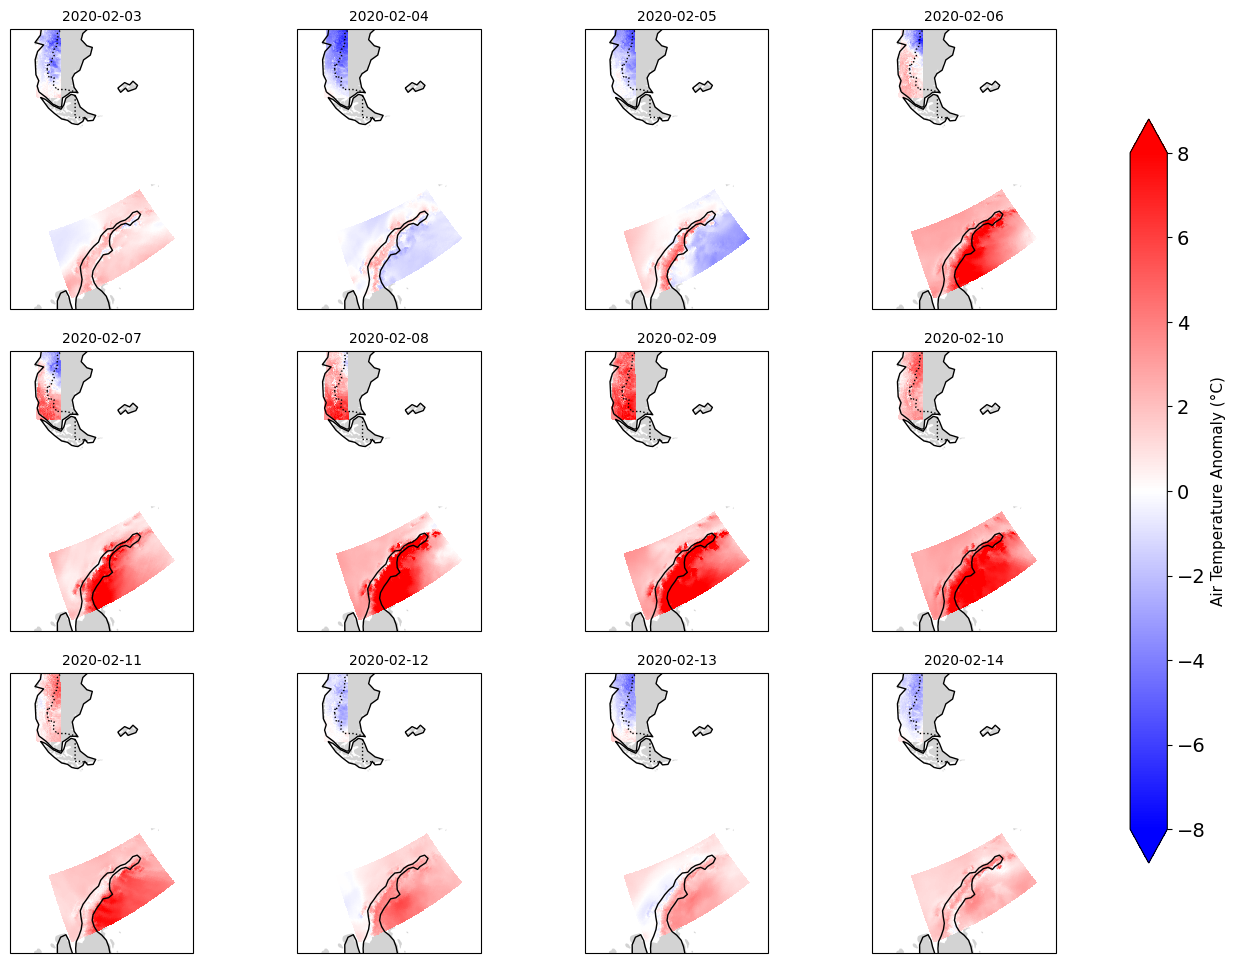

In [49]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Projections
proj_map = ccrs.Mercator()
proj_data = ccrs.PlateCarree()

date_start = '20200203'
date_end   = '20200214'

T2_anom_sel = T2_anom.sel(TIME=slice(date_start, date_end))
T2_anom_AP_sel = T2_anom_AP.sel(TIME=slice(date_start, date_end))

# Create 3x4 layout
fig, axes = plt.subplots(
    3,
    4,
    figsize=(16, 12),
    subplot_kw={"projection": proj_map},
    gridspec_kw={"wspace": 0.08, "hspace": 0.15},
)

# Flatten axes array for straightforward iteration
axes_flat = axes.flatten()

mesh = None
num_times = len(T2_anom_sel.TIME)

# Loop over each timestep (up to 12 max for a 3x4 layout)
for i in range(min(num_times, 12)):
    ax = axes_flat[i]
    setup_map(ax, proj_data=proj_data)
    
    # Plot main data
    mesh = ax.pcolormesh(
        LON, LAT, T2_anom_sel.isel(TIME=i),
        cmap='bwr', vmin=-8, vmax=8, shading="auto", transform=proj_data
    )
    
    # Plot AP data overlay
    ax.pcolormesh(
        LON_AP, LAT_AP, T2_anom_AP_sel.isel(TIME=i),
        cmap='bwr', vmin=-8, vmax=8, shading="auto", transform=proj_data
    )
    
    # Extract date string for title
    time_str = str(T2_anom_sel.TIME.values[i])[:10]
    ax.set_title(time_str, fontsize=10)

# Hide any unused subplots if TIME slice has fewer than 12 steps
for j in range(num_times, 12):
    fig.delaxes(axes_flat[j])

# Single horizontal colorbar across the bottom
cbar = plt.colorbar(
    mesh,
    ax=axes,
    orientation="vertical",
    fraction=0.03,
    pad=0.06,
    extend='both'
)
cbar.set_label("Air Temperature Anomaly (°C)", fontsize=11)


# Output directory for saving images
output_dir = "./fig"
os.makedirs(output_dir, exist_ok=True)

# Save figure named by date and close to free memory
save_path = os.path.join(output_dir, f"map_MAR_TT_case_2020.png")
print(save_path)
plt.savefig(save_path, dpi=200, bbox_inches="tight")


./fig/map_MAR_TT_case_2021.png


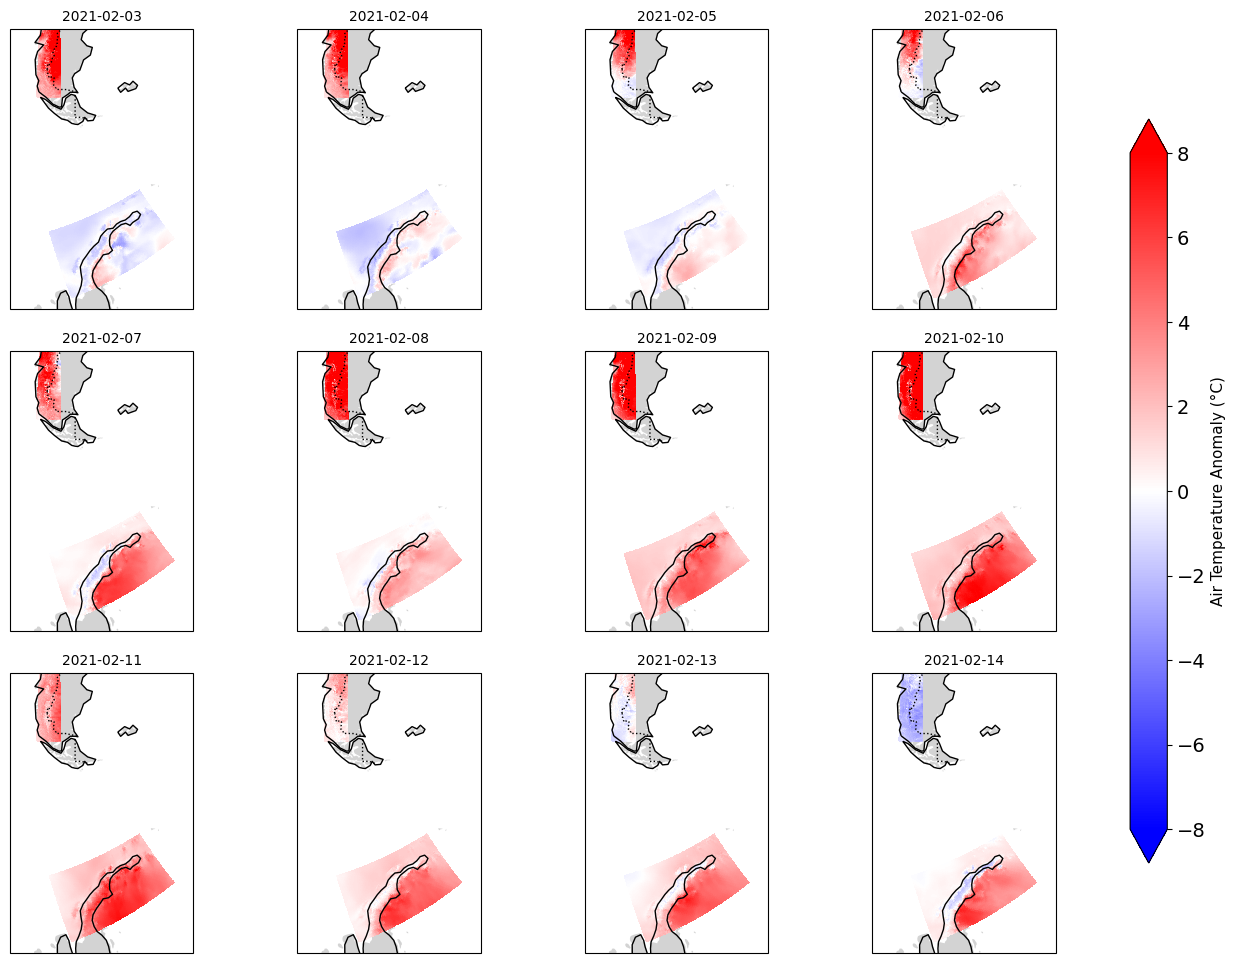

In [50]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Projections
proj_map = ccrs.Mercator()
proj_data = ccrs.PlateCarree()

date_start = '20210203'
date_end   = '20210214'

T2_anom_sel = T2_anom.sel(TIME=slice(date_start, date_end))
T2_anom_AP_sel = T2_anom_AP.sel(TIME=slice(date_start, date_end))

# Create 3x4 layout
fig, axes = plt.subplots(
    3,
    4,
    figsize=(16, 12),
    subplot_kw={"projection": proj_map},
    gridspec_kw={"wspace": 0.08, "hspace": 0.15},
)

# Flatten axes array for straightforward iteration
axes_flat = axes.flatten()

mesh = None
num_times = len(T2_anom_sel.TIME)

# Loop over each timestep (up to 12 max for a 3x4 layout)
for i in range(min(num_times, 12)):
    ax = axes_flat[i]
    setup_map(ax, proj_data=proj_data)
    
    # Plot main data
    mesh = ax.pcolormesh(
        LON, LAT, T2_anom_sel.isel(TIME=i),
        cmap='bwr', vmin=-8, vmax=8, shading="auto", transform=proj_data
    )
    
    # Plot AP data overlay
    ax.pcolormesh(
        LON_AP, LAT_AP, T2_anom_AP_sel.isel(TIME=i),
        cmap='bwr', vmin=-8, vmax=8, shading="auto", transform=proj_data
    )
    
    # Extract date string for title
    time_str = str(T2_anom_sel.TIME.values[i])[:10]
    ax.set_title(time_str, fontsize=10)

# Hide any unused subplots if TIME slice has fewer than 12 steps
for j in range(num_times, 12):
    fig.delaxes(axes_flat[j])

# Single horizontal colorbar across the bottom
cbar = plt.colorbar(
    mesh,
    ax=axes,
    orientation="vertical",
    fraction=0.03,
    pad=0.06,
    extend='both'
)
cbar.set_label("Air Temperature Anomaly (°C)", fontsize=11)


# Output directory for saving images
output_dir = "./fig"
os.makedirs(output_dir, exist_ok=True)

# Save figure named by date and close to free memory
save_path = os.path.join(output_dir, f"map_MAR_TT_case_2021.png")
print(save_path)
plt.savefig(save_path, dpi=200, bbox_inches="tight")


./fig/map_MAR_TT_case_2022.png


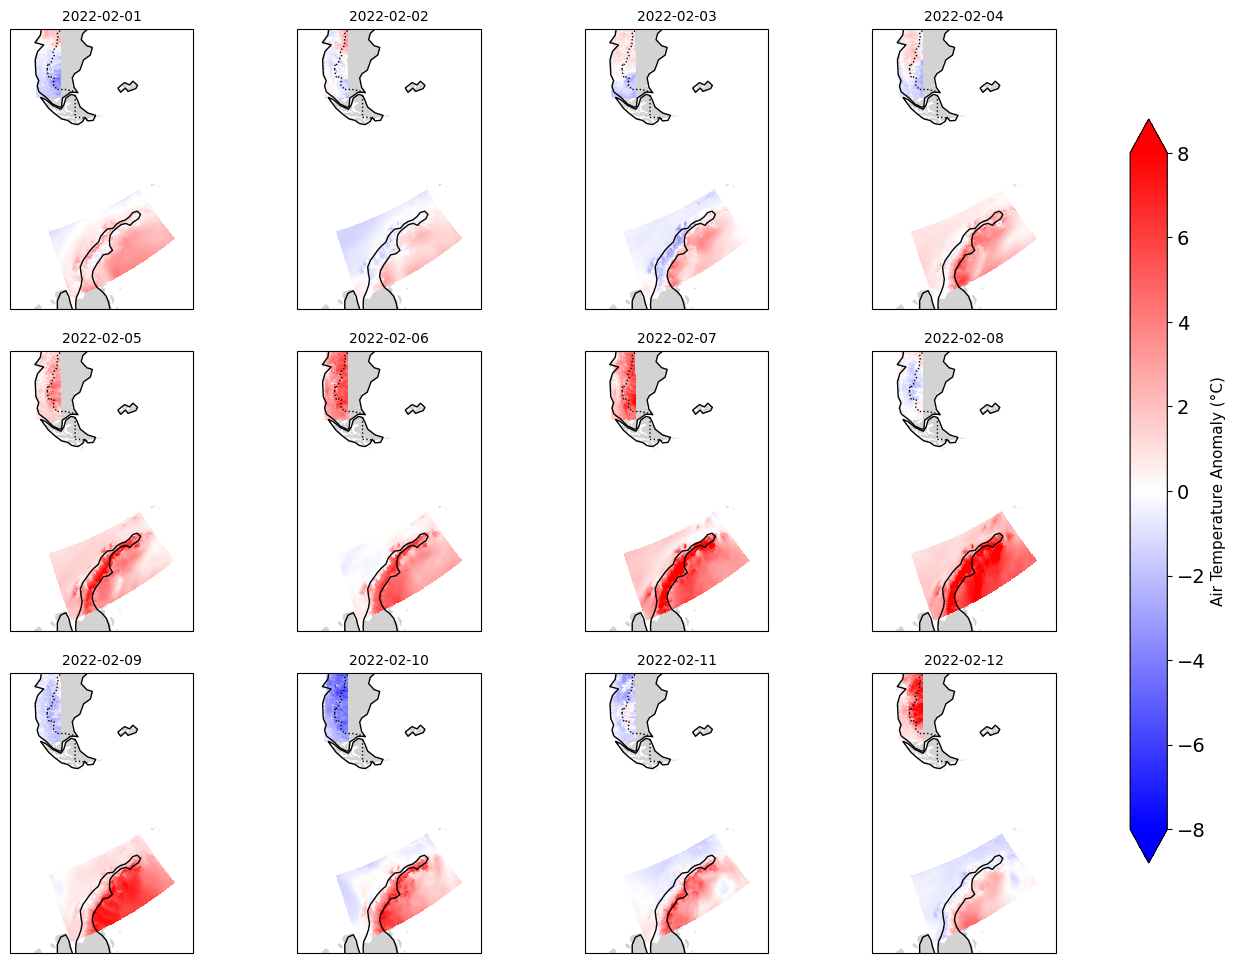

In [52]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Projections
proj_map = ccrs.Mercator()
proj_data = ccrs.PlateCarree()

date_start = '20220201'
date_end   = '20220212'

T2_anom_sel = T2_anom.sel(TIME=slice(date_start, date_end))
T2_anom_AP_sel = T2_anom_AP.sel(TIME=slice(date_start, date_end))

# Create 3x4 layout
fig, axes = plt.subplots(
    3,
    4,
    figsize=(16, 12),
    subplot_kw={"projection": proj_map},
    gridspec_kw={"wspace": 0.08, "hspace": 0.15},
)

# Flatten axes array for straightforward iteration
axes_flat = axes.flatten()

mesh = None
num_times = len(T2_anom_sel.TIME)

# Loop over each timestep (up to 12 max for a 3x4 layout)
for i in range(min(num_times, 12)):
    ax = axes_flat[i]
    setup_map(ax, proj_data=proj_data)
    
    # Plot main data
    mesh = ax.pcolormesh(
        LON, LAT, T2_anom_sel.isel(TIME=i),
        cmap='bwr', vmin=-8, vmax=8, shading="auto", transform=proj_data
    )
    
    # Plot AP data overlay
    ax.pcolormesh(
        LON_AP, LAT_AP, T2_anom_AP_sel.isel(TIME=i),
        cmap='bwr', vmin=-8, vmax=8, shading="auto", transform=proj_data
    )
    
    # Extract date string for title
    time_str = str(T2_anom_sel.TIME.values[i])[:10]
    ax.set_title(time_str, fontsize=10)

# Hide any unused subplots if TIME slice has fewer than 12 steps
for j in range(num_times, 12):
    fig.delaxes(axes_flat[j])

# Single horizontal colorbar across the bottom
cbar = plt.colorbar(
    mesh,
    ax=axes,
    orientation="vertical",
    fraction=0.03,
    pad=0.06,
    extend='both'
)
cbar.set_label("Air Temperature Anomaly (°C)", fontsize=11)


# Output directory for saving images
output_dir = "./fig"
os.makedirs(output_dir, exist_ok=True)

# Save figure named by date and close to free memory
save_path = os.path.join(output_dir, f"map_MAR_TT_case_2022.png")
print(save_path)
plt.savefig(save_path, dpi=200, bbox_inches="tight")
